In [1]:
%load_ext autoreload
%autoreload 2

%matplotlib inline
import matplotlib.pyplot as plt
import sigpy as sp
import pandas as pd
import sigpy.plot as pl
import numpy as np
import os
import jax as jx
ksp = np.load(r"/Users/ayman/Library/CloudStorage/OneDrive-King'sCollegeLondon/Project/Sigpytutorial/projection_ksp.npy")
coord = np.load(r"/Users/ayman/Library/CloudStorage/OneDrive-King'sCollegeLondon/Project/Sigpytutorial/projection_coord.npy")


import sys
from pathlib import Path

project_root = Path.cwd().parents[1]
sys.path.append(str(project_root))

print(project_root)

import aymansigmri as asm

/Users/ayman/Desktop/MSc Project Local/MSc-Project-ZTE


## Goal: Implement Algorithm 4.1

In [8]:
width=4
gap = 2
num_iters = 50

resize_wid=1024
rw_div2 = int(resize_wid/2)

inner_wid=100
indiv2 = int(inner_wid/2)

## Set up ZTE style data
- few changes because we have only one coil

In [5]:
def plot_mask(isolated_kspace, mask, zte_radial_coords, zte_radial_kspace,
              innersidelen, sidelencart, sidelenrad, n, eps=0.3):

    # Accept (nx, ny) or (1, nx, ny): drop a singleton coil axis if present
    cart = np.squeeze(isolated_kspace)
    mask2d = np.squeeze(mask)
    if cart.ndim != 2 or mask2d.ndim != 2:
        raise ValueError(f"Expected 2D kspace/mask, got {isolated_kspace.shape} and {mask.shape}")

    all_coords = zte_radial_coords.reshape(-1, 2)
    # Radial kspace: use it directly if it has no coil axis, otherwise take coil 0
    rad_vals = zte_radial_kspace if zte_radial_kspace.size == len(all_coords) else zte_radial_kspace[0]
    rad_vals = np.abs(rad_vals).ravel()

    # radius of the dead-time gap = distance of the nth point along a spoke from origin
    gap_radius_rad = np.linalg.norm(zte_radial_coords[0, n-1]) + eps
    gap_radius_cart = 2 * np.linalg.norm(zte_radial_coords[0, n-1]) + eps
    centre = innersidelen / 2

    def style(a, title, xlabel, ylabel, lim, circle_xy, circle_r):
        a.set_title(title)
        a.set_xlabel(xlabel)
        a.set_ylabel(ylabel)
        a.set_xlim(*lim)
        a.set_ylim(*lim)
        a.xaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
        a.yaxis.set_minor_locator(plt.MultipleLocator(1, offset=0.5))
        a.grid(visible=True, which='minor', linewidth=1)
        a.xaxis.set_major_locator(plt.MultipleLocator(1))
        a.yaxis.set_major_locator(plt.MultipleLocator(1))
        a.add_patch(plt.Circle(circle_xy, circle_r, fill=False, ec='red', lw=4,
                               ls='--', zorder=10, label='Dead-time gap'))
        a.legend()

    cart_lim = (centre - sidelencart, centre + sidelencart)
    rad_lim = (-(sidelenrad // 2), sidelenrad // 2)

    fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(30, 8))

    # Cartesian kspace
    im = ax[0].imshow(np.abs(cart), cmap='viridis', origin='lower')
    fig.colorbar(im, ax=ax[0], label='kspace value')
    style(ax[0], 'Cartesian', 'kx', 'ky', cart_lim, (centre, centre), gap_radius_cart)

    # Mask
    yy, xx = np.mgrid[0:mask2d.shape[0], 0:mask2d.shape[1]]
    mask_flat = mask2d.ravel().astype(bool)
    ax[1].scatter(xx.ravel()[mask_flat], yy.ravel()[mask_flat], c='yellow', s=300, marker='s', zorder=3, label='mask True')
    ax[1].scatter(xx.ravel()[~mask_flat], yy.ravel()[~mask_flat], c='purple', s=300, marker='s', zorder=3, label='mask False')
    ax[1].set_aspect('equal')
    style(ax[1], 'Centre mask', 'x', 'y', cart_lim, (centre, centre), gap_radius_cart)

    # Radial kspace
    im2 = ax[2].scatter(all_coords[:, 0], all_coords[:, 1], c=rad_vals, cmap='viridis')
    fig.colorbar(im2, ax=ax[2], label='kspace value')
    ax[2].set_aspect('equal')
    style(ax[2], 'Radial', 'kx', 'ky', rad_lim, (0, 0), gap_radius_rad)

    plt.show()


In [9]:
zte_radial_kspacedlt, zte_radial_coordsdlt, zte_radial_kspacezero, zte_radial_coordszero, mask = asm.generate_zte_data(ksp=ksp, coord=coord, n_missing=(gap), undersampling_factor=1)


cartesian_zte = asm.nufft_gridding(kspace=zte_radial_kspacezero, coords=zte_radial_coordszero)

enlarged_imgrid = asm.zero_padding(cart_kspace=cartesian_zte, resize_factor=4, outputtype_kspace=False)

englarged_im = np.sum(np.abs(enlarged_imgrid)**2, axis=0)**0.5

enlarged_kspace = sp.fft(englarged_im)

In [10]:
cx, cy = enlarged_kspace.shape[0] // 2, enlarged_kspace.shape[1] // 2
N = inner_wid/2
start, end = int(cx-N), int(cx+N)
inner_mask = np.ones(enlarged_kspace.shape, dtype=int)
inner_mask[start:end, start:end] = 0
inner_region = enlarged_kspace[start:end, start:end]

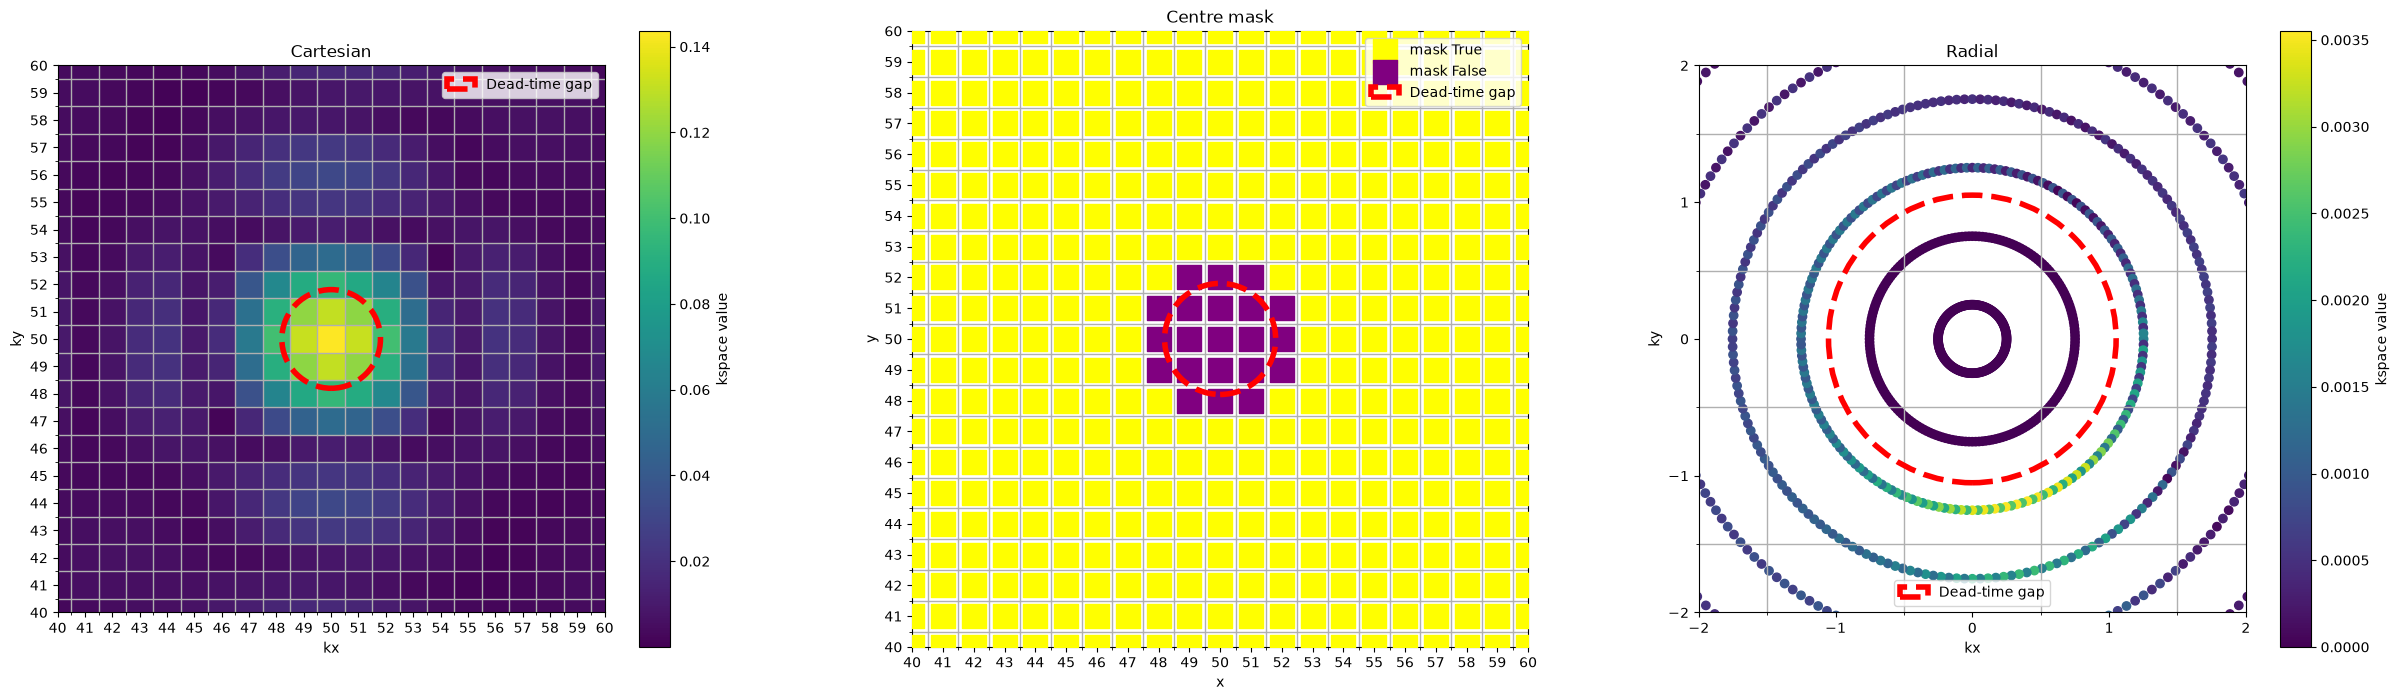

In [11]:
cy, cx = inner_wid // 2, inner_wid // 2
r = 2
yy, xx = np.ogrid[:inner_wid, :inner_wid]
mask = (yy - cy)**2 + (xx - cx)**2 > r**2 +2

#mask[(cx-5):(cx+6), cy] = False
#mask[(cx), (cy-5):(cy+6)] = False


masked_inner = inner_region.copy()
masked_inner[~mask] = 0

inner_removed = inner_region.copy()
inner_removed[~mask] = 0

totalwid = 1024
totaldiv = totalwid // 2

mask2 = np.ones((totalwid, totalwid), dtype=bool)

mask2[(indiv2-3):(indiv2+3), indiv2:indiv2+1] = False
mask2[(indiv2), (indiv2-2):(indiv2+3)] = False

plot_mask(inner_region, mask=mask, zte_radial_coords=zte_radial_coordszero, zte_radial_kspace=zte_radial_kspacezero, innersidelen=inner_wid,sidelencart=10,sidelenrad=4, n=2)

### Functions for inner loop and filling framework

In [62]:
def softimpute_ALS(X_H, M_H, rank, lamda, n_iters):
        I = np.eye(rank)
        m,n = np.shape(X_H)
        U = np.random.randn(m, rank) + 1j * np.random.randn(m, rank)
        V = np.random.randn(n, rank) + 1j * np.random.randn(n, rank)

        D = I.copy()


        A = np.dot(U,D)
        B = np.dot(V,D)
        iter_count = 0
        ABt = A @ B.conj().T
        
        while iter_count < n_iters:
            X_star = np.where(M_H, X_H, ABt)
            X_star1H = X_star.copy()
            A = X_star @ B @ np.linalg.inv(B.conj().T @ B + lamda*I)
            ABt = A @ B.conj().T
            X_star = np.where(M_H, X_H, ABt)
            B = X_star.conj().T @ A @ np.linalg.inv(A.conj().T @ A + lamda*I)
            ABt = A @ B.conj().T
            iter_count += 1
        return(ABt, X_star1H)

def LORAKS_imputeals(n_iters, window_size, cartesian_inputkspace, dtg_mask, rank, lamda, stride):
    ksp_forhankel = cartesian_inputkspace.copy()
    ksp_zerod = ksp_forhankel * dtg_mask
    hankel_matrix, n_coils, Numx, Numy = asm.hankel_2(kspace=ksp_zerod, w=window_size, s=stride)
    mask_coiled = np.broadcast_to(dtg_mask, (cartesian_inputkspace.shape))
    masked_hankel, *_ = asm.hankel_2(mask_coiled, window_size, s=stride)
    masked_hankel = np.real(masked_hankel) > 0.5
    
    
    filled_hankel, X_star1 = softimpute_ALS(X_H = hankel_matrix, M_H = masked_hankel, rank = rank, lamda = lamda, n_iters=n_iters)

    kspace_cart_coils_recon = asm.hankel_H_averaged_2(filled_hankel, n_coils=ksp_forhankel.shape[0], Nx=ksp_forhankel.shape[1], Ny=ksp_forhankel.shape[2], w=window_size, s=stride)
    kspace_cart_coils_recon = np.where(dtg_mask, cartesian_inputkspace, kspace_cart_coils_recon)
    output_kspace = kspace_cart_coils_recon.copy()

    return output_kspace, masked_hankel

## Testing